<a href="https://colab.research.google.com/github/JLettsSJU931/Machine-Learning-FA26/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Task 1:** Load the dataset into a Pandas DataFrame.
Here, I simply install the UCI repository, fetch the heart disease data, and stuff it in a dataframe named "df".

In [235]:
!pip install ucimlrepo
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo

# fetch dataset
heart_disease = fetch_ucirepo(id=45)
# data (as pandas dataframes)
x = heart_disease.data.features
y = heart_disease.data.targets
df = pd.concat([x, y], axis=1)

# **Task 2:** Use structural inspection methods (head(), info(), describe()) to analyze continuous and categorical features.
This is one is self explanatory I feel.

In [236]:
print("Data Head")
display(df.head())
print("--------------")
print("Data Info")
df.info()
print("--------------")
print("Data Description")
display(df.describe())

Data Head


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


--------------
Data Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB
--------------
Data Description


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


# **Task 3:** Quantify and handle any missing or implicit missing values across the columns (checking for non-standard placeholders such as ? strings) and implement a structured imputation strategy using Scikit-Learn's SimpleImputer.
First I make a new dataframe where all instances of "?" are replaced with a np.nan value, and I print a count of how many na values there are in each column. Next, I create a SimpleImputer to replace any na values with the median of its column (don't want to risk having decimals where they don't belong). I list the columns with na values and do a fit transform on those columns, printing proof that the na values are gone.

In [237]:
from sklearn.impute import SimpleImputer

full_df = df.replace("?", np.nan)
print('Before:')
display(full_df.isna().sum())
print('----------')
imp = SimpleImputer(missing_values=np.nan, strategy='median')
false_columns = ['ca', 'thal']
full_df[false_columns] = imp.fit_transform(full_df[false_columns])
print("After")
display(full_df.isna().sum())

Before:


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


----------
After


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


# **Task 4:** Isolate numerical and categorical features, then build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling (StandardScaler or MinMaxScaler) to numerical columns and encoding (OneHotEncoder) to categorical columns.
Here I make two transformers to start: a numeric and a categorical transformer, each with their own respective needs fufilled (scaling for num; encoding for cat). I then combine those two transformer into one full transformation pipeline to be used on the dataframe.

In [238]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector

num_trans = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_trans = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
transformer = ColumnTransformer(transformers=[
    ("num", num_trans, make_column_selector(dtype_include=np.number)),
    ("cat", cat_trans, make_column_selector(dtype_include=["object", "category", "string", "bool"])),
])
true_df = transformer.fit_transform(full_df)

# **Task 5:** Instantiate and train a Support Vector Classifier (SVC) configured with kernel='rbf' and probability=True within your pipeline, then evaluate performance using a confusion matrix, classification report, and ROC-AUC curve.
Now here is where things got a bit messy. It starts normal with the creation of the SVC pipeline, including the transformer from Task 4 and making sure to include the rbf kernel and the probability=True hyperparameters. However, when it got to defining x and y, no mater what I did, I could not get y in its natural state to work in the roc_auc_score function, saying it was a multiclass function. So, after some trial and error, I figured out I could map all of the values that pertained to heart disease to "1" and vice versa, allowing y to now be binary and thus work in the roc_curve function. Past this, things go as normal: make the x/y training and testing variables, put the training variables into the svc pipeline, make the prediction and probability variables, and generate the performance evaluating visualizers.


 Confusion matrix:
[[31  5]
 [14 11]]

 Classification report:
              precision    recall  f1-score   support

           0       0.69      0.86      0.77        36
           1       0.69      0.44      0.54        25

    accuracy                           0.69        61
   macro avg       0.69      0.65      0.65        61
weighted avg       0.69      0.69      0.67        61

ROC_AUC: 0.7533333333333333


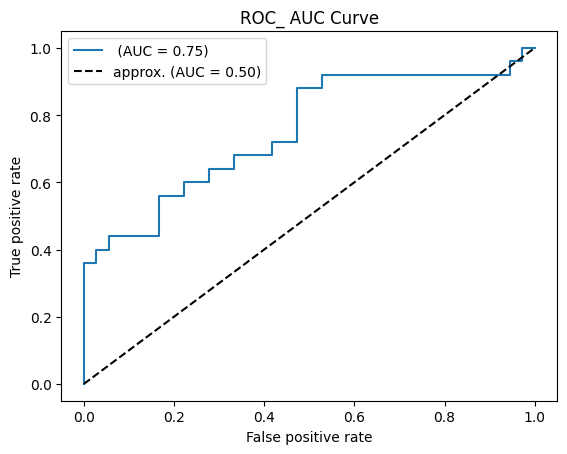

In [245]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import auc
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay
from sklearn.svm import SVC

svc_pipeline = Pipeline(steps=[
    ('transformer', transformer),
    ('svc', SVC(C=1.0, kernel='rbf', probability=True, random_state=69))
])
y = full_df['ca'].map({1: 1, 2:1, 3:1, 0: 0})
x = full_df.drop(columns=["ca"])
true = y.notna()
x, y = x.loc[true], y.loc[true]
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=69, stratify=y)
svc_df = svc_pipeline.fit(X_train, y_train)
y_pred = svc_pipeline.predict(X_test)
y_prob = svc_pipeline.predict_proba(X_test)[:, 1]

print("\n Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\n Classification report:")
print(classification_report(y_test, y_pred))

auc_score = roc_auc_score(y_test, y_prob)
print(f"ROC_AUC: {auc_score}")

fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f" (AUC = {auc_score:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="approx. (AUC = 0.50)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC_ AUC Curve")
plt.legend()
plt.show()





# **Task 6:** Instantiate and train a Decision Tree Classifier (DecisionTreeClassifier) within your pipeline, and evaluate its performance using identical metrics to compare against your SVC model.
Once again the y value here is mapped to be binary. I basically do the same thing here, just instead of using the svc I use the Decision Trees. So, in that case, ditto.


 Confusion matrix:
[[28  8]
 [10 15]]

 Classification report:
              precision    recall  f1-score   support

           0       0.74      0.78      0.76        36
           1       0.65      0.60      0.62        25

    accuracy                           0.70        61
   macro avg       0.69      0.69      0.69        61
weighted avg       0.70      0.70      0.70        61

ROC_AUC: 0.6611111111111111


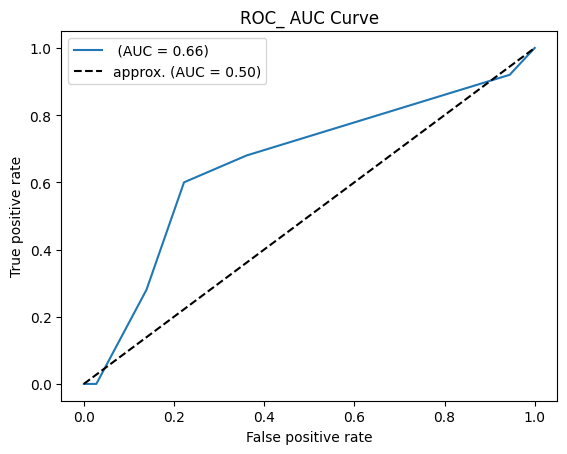

In [240]:
from sklearn.tree import DecisionTreeClassifier

dt_pipeline = Pipeline(steps=[
    ('transformer', transformer),
    ('dt', DecisionTreeClassifier(max_depth=3, random_state=69))
])

dt_df = dt_pipeline.fit(X_train, y_train)
y_pred = dt_pipeline.predict(X_test)
y_prob = dt_pipeline.predict_proba(X_test)[:, 1]

print("\n Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\n Classification report:")
print(classification_report(y_test, y_pred))

auc_score = roc_auc_score(y_test, y_prob)
print(f"ROC_AUC: {auc_score}")

fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f" (AUC = {auc_score:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="approx. (AUC = 0.50)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC_ AUC Curve")
plt.legend()
plt.show()

# **Task 7:** Perform hyperparameter tuning using GridSearchCV on your SVC pipeline (exploring parameters such as C and gamma) to optimize cross-validation performance.
I first make a list of parameters of svc (those parameters being C and gamma), before making a gsc based on the svc created inside the pipeline in Task 5. I then fit the training variables on the gridsearch and print out the ideal hyperparameters for this dataframe.

In [241]:
from sklearn.model_selection import GridSearchCV

params = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],

}
gsc = GridSearchCV(estimator = svc_pipeline['svc'], param_grid = params, cv=3)
gsc.fit(X_train, y_train)
print("Best Parameters:", gsc.best_params_)
print("Best Cross-Validation Score:", gsc.best_score_)

Best Parameters: {'C': 1, 'gamma': 0.001}
Best Cross-Validation Score: 0.6613168724279835


# **Task 8:** Generate a decision tree visualization (plot_tree) or inspect feature importances to interpret how the model separates patients with heart disease from healthy patients.
To start, I reset x to be its original value to be sure all of the feature names are displayed correctly. I then use the decision tree to rank the features based on their importance values. Finally, I create a plot tree using the columns of x as well as y=0 being healthy and y = 1 being heart disease.

--- Feature Importances ---
thal        0.533793
age         0.300433
chol        0.100262
trestbps    0.065512
dtype: float64




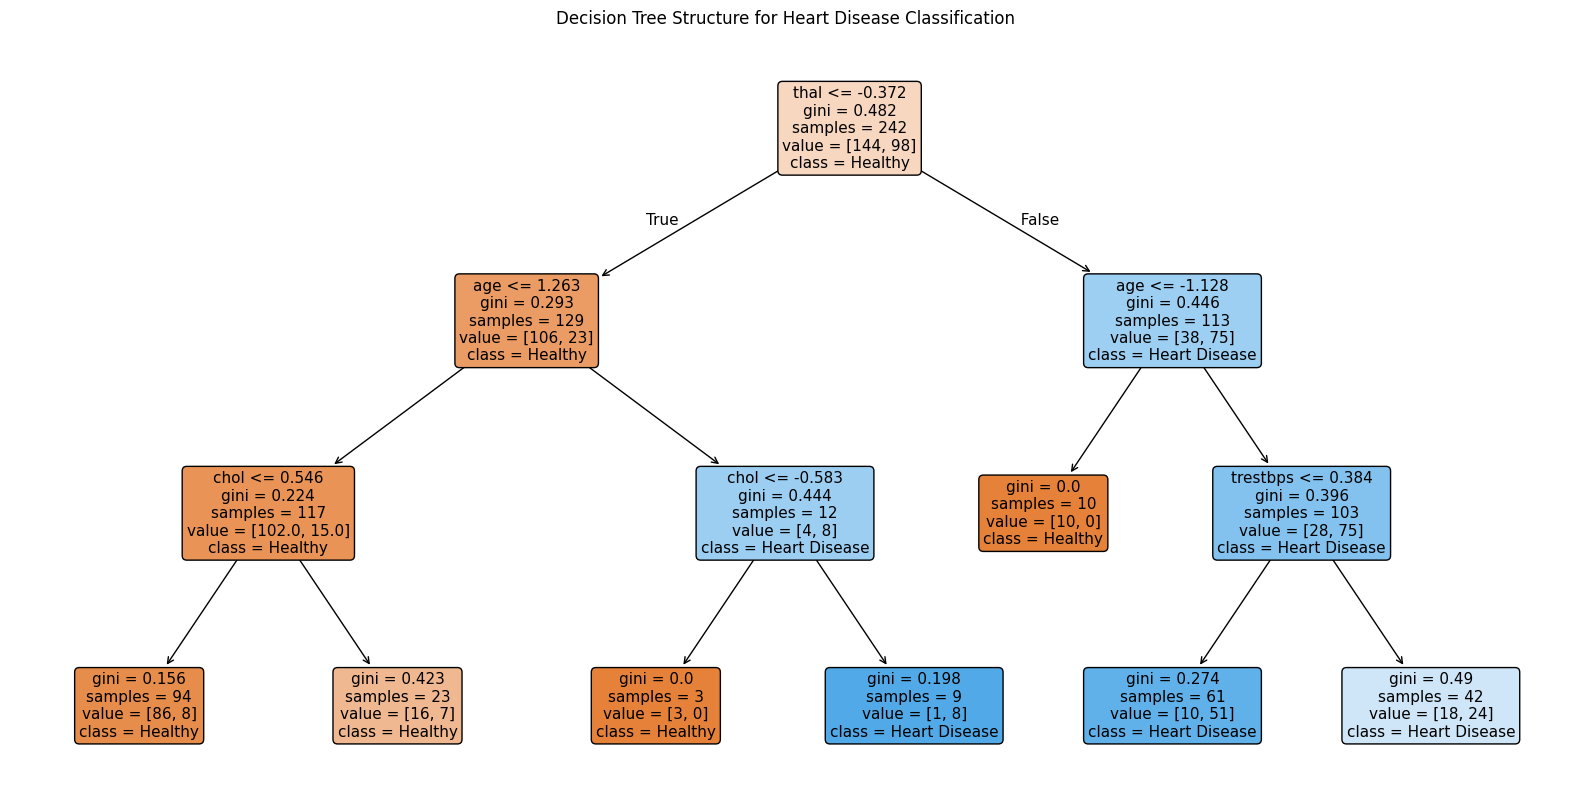

In [248]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

x = heart_disease.data.features

importances = pd.Series(dt_pipeline['dt'].feature_importances_, index=x.columns)
print("--- Feature Importances ---")
print(importances[importances > 0].sort_values(ascending=False))
print("\n")


plt.figure(figsize=(20, 10))
plot_tree(
    dt_pipeline['dt'],
    feature_names=list(x.columns),
    class_names=['Healthy', 'Heart Disease'],
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Decision Tree Structure for Heart Disease Classification")
plt.show()